# Paper results: Experimental Evaluation

Figures, tables and key numbers for Section 4 and the appendices:

| Section | Question | Theory | Main figures |
|---|---|---|---|
| 4.2 Convergence and cost | Does Vanilla finish? Where does its runtime go, and what speedup does stopping at K give? | Theorem 2, parallel execution | runtime anatomy, speedup |
| 4.3 Ground truth | What does the single-hit rule cost in recall and false positives? | Theorems 1 and 3, weak/strong | FP vs bound, hit counts |
| 4.4 Real data | Which features does Greedy add, and does a downstream model notice? | Theorem 1, weak/strong | fates, NI, α strip |
| Appendix B | Reduced shadows | K/(r+1) bound | FP vs 1/(r+1) |

The source is the augmented copy `<run>_aug` (`runner/augment_coupled.py`) when it
exists, otherwise the original run (coupled and history sections are skipped).
Diagnostics stay in `publication_analysis.ipynb`. Nothing here fits models.

**Greedy** means the prespecified full-shadow Greedy run (`j=1`); its masks are identical
to the parallel run (checked below), which matters only for timing. **Greedy coupled** is
Greedy evaluated on the first K iterations of the very Vanilla fit it is compared with.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "benchmarks" / "runner" / "experiment_run.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from within this repository")
ANALYSIS_DIR = ROOT / "benchmarks" / "analysis" / "publication"
sys.path.insert(0, str(ANALYSIS_DIR))
import analysis_helpers as ah

RUNS = ROOT / "benchmarks" / "data" / "publication_runs"
RUN_DIR = Path(os.environ.get("PUBLICATION_RUN_DIR") or
               next(p for p in [RUNS / f"{ah.RUN_NAME}_aug", RUNS / ah.RUN_NAME] if p.exists()))
FOCUS_ALPHA = 0.001
OUTPUT_DIR = ANALYSIS_DIR / "outputs" / RUN_DIR.name / "paper"
(OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)
ah.paper_style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)
FACTS = {}

def show(fig, name):
    ah.save_figure(fig, OUTPUT_DIR, name)
    display(fig)
    plt.close(fig)

def save_latex(table, name, caption, label, **kwargs):
    text = ah.latex_table(table, caption, label, **kwargs)
    (OUTPUT_DIR / "tables" / f"{name}.tex").write_text(text, encoding="utf-8")
    return text

In [2]:
run = ah.load_run(RUN_DIR)
config = run.manifest["config"]
complete = ah.complete_blocks(run)
summary = ah.summary_table(complete)
paired = ah.paired_comparisons(complete)
ni = ah.noninferiority(paired, run)
histories, trajectories = ah.load_histories(RUN_DIR)
HAS_COUPLED = complete.Method.eq(ah.COUPLED).any()
HAS_HISTORY = not histories.empty
sets = ah.coupled_sets(complete, run.manifest) if HAS_COUPLED else pd.DataFrame()
datasets = config["datasets"]
p_of = complete.groupby("Dataset").N_Features.first()
# Real datasets ordered by dimensionality throughout; XOR only in the appendix.
REAL = sorted([n for n, (kind, _) in datasets.items() if kind == "real"], key=lambda n: p_of[n])
SYNTHETIC = [n for n, (kind, spec) in datasets.items() if kind == "synthetic" and spec["kind"] != "xor"]
PARALLEL = ah.greedy_parallel_label(complete)
PARALLEL_Q = ah.parallel_quantity(complete)
display(Markdown(
    f"**Run:** `{RUN_DIR.name}` | prespecified design complete: **{run.complete}** | "
    f"coupled Greedy: **{HAS_COUPLED}** | Vanilla histories: **{len(histories)}** refits  \n"
    f"Real datasets (by p): {REAL}; synthetic: {SYNTHETIC}."))

**Run:** `run_20260926_102546_793908_aug` | prespecified design complete: **True** | coupled Greedy: **True** | Vanilla histories: **33** refits  
Real datasets (by p): ['Madelon', 'Isolet', 'Riboflavin', 'Gisette', 'Arcene', 'Dexter']; synthetic: ['reference', 'n_features_2000', 'signal_0.5', 'kind_null'].

**Coupled identities, re-checked on every logged row** (independently of the augmentation
log): Vanilla's strict and rough-fix sets inside coupled Greedy's set (Theorem 1), strong
confirmations inside Vanilla's strict set, and K equal to the logged Greedy budget.

In [3]:
if HAS_COUPLED:
    checks = ah.verify_coupled(complete)
    display(checks.filter(regex="Theorem|Strong|K_").agg(["sum", "count"]))
    FACTS["coupled_identity_checks"] = {c: f"{int(checks[c].sum())}/{len(checks)}"
                                        for c in checks.filter(regex="Theorem|Strong|K_").columns}

,Theorem1_Strict,Theorem1_Rough_Fix,Strong_In_Strict,K_Matches_Greedy
sum,495,495,495,495
count,495,495,495,495


## 4.1 Setup table

In [4]:
sizes = complete.groupby("Dataset").agg(n=("N_Train", "first"), n_test=("N_Test", "first"),
                                        p=("N_Features", "first"), Task=("Task", "first"))
rows = []
for name in REAL + [n for n, (kind, _) in datasets.items() if kind == "synthetic"]:
    kind, spec = datasets[name]
    s = sizes.loc[name]
    row = {"Dataset": name, "Suite": kind, "Task": s.Task, "n": int(s.n + s.n_test), "p": int(s.p),
           "Relevant": len(ah.relevant_features(spec)) if kind == "synthetic" else None}
    row.update({f"K (α={a:g})": int(np.ceil(np.log2(s.p / a))) for a in sorted(config["alphas"], reverse=True)})
    rows.append(row)
setup = pd.DataFrame(rows)
display(setup)
latex = setup.assign(Relevant=setup.Relevant.map(lambda v: "--" if pd.isna(v) else f"{int(v)}"),
                     n=setup.n.map("{:,}".format), p=setup.p.map("{:,}".format)).drop(columns="Suite")
save_latex(latex, "setup_datasets", "Datasets, relevant features and Greedy iteration budget $K$.", "tab:datasets", group_rules=False);

,Dataset,Suite,Task,n,p,Relevant,K (α=0.1),K (α=0.001),K (α=1e-05)
0,Madelon,real,class,2600,500,NaN,13,19,26
1,Isolet,real,class,7797,617,NaN,13,20,26
2,Riboflavin,real,reg,71,4088,NaN,16,22,29
3,Gisette,real,class,7000,5000,NaN,16,23,29
4,Arcene,real,class,200,10000,NaN,17,24,30
5,Dexter,real,class,600,20000,NaN,18,25,31
6,reference,synthetic,class,1000,500,25.0,13,19,26
7,n_features_2000,synthetic,class,1000,2000,25.0,15,21,28
8,signal_0.5,synthetic,class,1000,500,25.0,13,19,26
9,kind_xor,synthetic,class,1000,500,2.0,13,19,26


## 4.2 Convergence and computational cost

**Does Vanilla finish?** Every fold: whether it reached the iteration cap, and how many
tentative features the rough fix had to promote.

In [5]:
convergence = ah.vanilla_convergence(complete, run.manifest)
display(convergence[["Dataset", "Alpha", "K", "Median_Iterations", "Fraction_At_Cap",
                     "Fraction_Rough_Fix_Used", "Mean_Rough_Fix_Promoted", "Max_Rough_Fix_Promoted",
                     "Median_Iteration_Ratio"]])
real_conv = convergence[convergence.Dataset.isin(REAL)]
FACTS["vanilla_cap_fraction_by_dataset_alpha"] = real_conv.set_index(["Dataset", "Alpha"]).Fraction_At_Cap.round(3).to_dict()
FACTS["datasets_always_at_cap"] = sorted(real_conv.groupby("Dataset").Fraction_At_Cap.min().loc[lambda s: s.eq(1)].index)
FACTS["rough_fix_promoted_max"] = int(convergence.Max_Rough_Fix_Promoted.max())
FACTS["rough_fix_used_fraction_real"] = real_conv.set_index(["Dataset", "Alpha"]).Fraction_Rough_Fix_Used.round(2).to_dict()

,Dataset,Alpha,K,Median_Iterations,Fraction_At_Cap,Fraction_Rough_Fix_Used,Mean_Rough_Fix_Promoted,Max_Rough_Fix_Promoted,Median_Iteration_Ratio
0,Arcene,1.0000e-05,30,512.0,1.0000,1.0000,70.2667,111,17.0667
1,Arcene,1.0000e-03,24,512.0,1.0000,1.0000,60.9333,93,21.3333
2,Arcene,1.0000e-01,17,512.0,1.0000,1.0000,46.4667,79,30.1176
3,Dexter,1.0000e-05,31,512.0,0.9333,1.0000,12.0000,17,16.5161
4,Dexter,1.0000e-03,25,512.0,0.6000,1.0000,10.8667,17,20.4800
5,Dexter,1.0000e-01,18,475.0,0.4667,1.0000,8.2667,12,26.3889
6,Gisette,1.0000e-05,29,512.0,1.0000,1.0000,103.9333,119,17.6552
7,Gisette,1.0000e-03,23,512.0,1.0000,1.0000,84.2667,93,22.2609
8,Gisette,1.0000e-01,16,512.0,1.0000,1.0000,66.8667,80,32.0000
9,Isolet,1.0000e-05,26,512.0,0.9333,1.0000,8.8667,11,19.6923


**Where Vanilla's runtime goes** (full Vanilla refits with history, focus α, three folds
per dataset). Blue: features still tentative; gray: cumulative share of the run's own
wall-clock time; dashed: Greedy's budget K. At K, Vanilla has resolved most features but
spent only part of its runtime; the remaining tentatives absorb the rest.

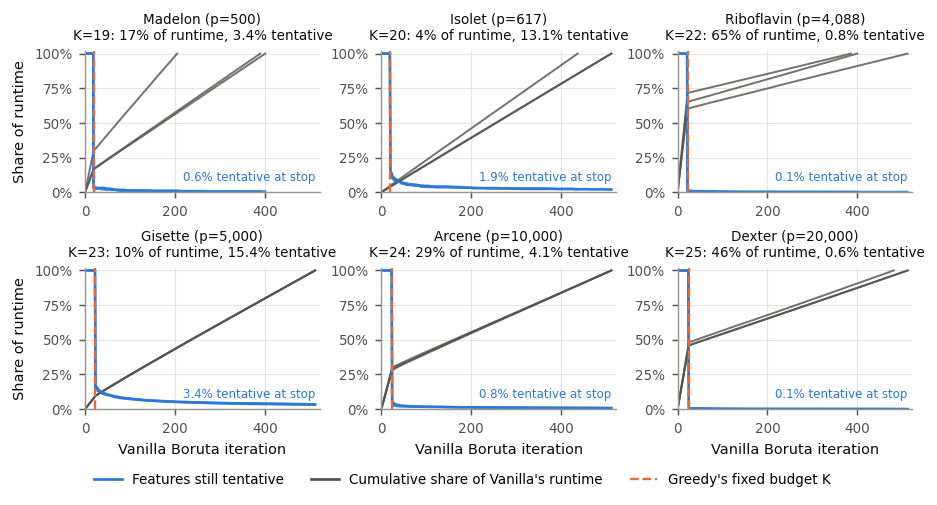

,Refits,Iterations,Stop,Runtime_Share_At_K,Tentative_At_K,Final_Tentative,Same_Run_Speedup,Session_Time_Ratio
Dataset,,,,,,,,
Arcene,3,512.0,iteration_cap:3,0.285,0.041,76.0,3.505,0.894
Dexter,3,512.0,"iteration_cap:2, early_stopping:1",0.457,0.006,10.0,2.187,0.942
Gisette,3,512.0,iteration_cap:3,0.095,0.154,169.0,10.478,0.933
Isolet,3,512.0,"iteration_cap:2, early_stopping:1",0.040,0.131,12.0,25.074,0.922
Madelon,3,390.0,early_stopping:3,0.169,0.034,3.0,5.931,0.547
Riboflavin,3,400.0,"early_stopping:2, iteration_cap:1",0.651,0.008,6.0,1.537,0.656
kind_null,3,98.0,"resolved:2, early_stopping:1",0.601,0.012,0.0,1.665,0.533
kind_xor,3,119.0,"resolved:2, early_stopping:1",0.544,0.014,0.0,1.839,0.573
n_features_2000,3,399.0,"early_stopping:2, resolved:1",0.294,0.007,4.0,3.396,0.984


In [6]:
if HAS_HISTORY:
    show(ah.runtime_anatomy_plot(trajectories, FOCUS_ALPHA, REAL), "fig_runtime_anatomy")
    h = histories[histories.Alpha.eq(FOCUS_ALPHA)].copy()
    at_k = trajectories[trajectories.iteration.eq(trajectories.K)][["Partition_ID", "Alpha", "Tentative_Fraction"]]
    h = h.merge(at_k, on=["Partition_ID", "Alpha"])
    h["Runtime_Share_At_K"] = h.Time_At_K_Sec / h.Selection_Time_Sec
    anatomy = h.groupby("Dataset").agg(Refits=("Fold", "size"), Iterations=("Iterations", "median"),
        Stop=("Stop_Reason", lambda s: ", ".join(f"{k}:{v}" for k, v in s.value_counts().items())),
        Runtime_Share_At_K=("Runtime_Share_At_K", "median"), Tentative_At_K=("Tentative_Fraction", "median"),
        Final_Tentative=("Final_Tentative", "median"), Same_Run_Speedup=("Same_Run_Speedup", "median"),
        Session_Time_Ratio=("Session_Time_Ratio", "median"))
    display(anatomy.round(3))
    FACTS["runtime_share_at_K"] = anatomy.Runtime_Share_At_K.round(3).to_dict()
    FACTS["tentative_share_at_K"] = anatomy.Tentative_At_K.round(4).to_dict()
    FACTS["history_stop_reasons"] = anatomy.Stop.to_dict()
    FACTS["history_session_time_ratio_range"] = [round(histories.Session_Time_Ratio.min(), 3),
                                                 round(histories.Session_Time_Ratio.max(), 3)]
else:
    display(Markdown("_No Vanilla history refits yet: run `publication/augment.ps1`._"))

**Speedup.** Per dataset at the focus α: the naive expectation (Vanilla iterations / K),
the speedup Vanilla itself would get if stopped at iteration K (same refit, so no
cross-session timing), and the observed speedups of Greedy. The cross-session variant
(logged Vanilla time / coupled prefix time) is kept in the table only: the augmentation
session ran up to ~2x faster than the original on some datasets, which biases it.

Quantity,Greedy parallel (j=7),Greedy serial (j=1),Iteration ratio,Per-iteration cost ratio,Same run stopped at K (history),Same work stopped at K
Dataset,,,,,,
Arcene,13.52,3.63,21.33,5.34,3.51,4.00
Dexter,8.50,2.17,20.48,9.28,2.19,2.12
Gisette,15.84,10.57,22.26,2.45,10.48,9.08
Isolet,57.20,25.01,25.60,0.94,25.07,26.69
Madelon,18.06,4.60,17.37,2.55,5.93,6.55
Riboflavin,1.68,1.57,19.36,10.45,1.54,1.77
kind_null,8.67,1.80,7.47,2.06,1.66,3.09
kind_xor,9.38,1.83,6.53,2.50,1.84,3.37
n_features_2000,8.49,3.38,19.00,5.60,3.40,3.28


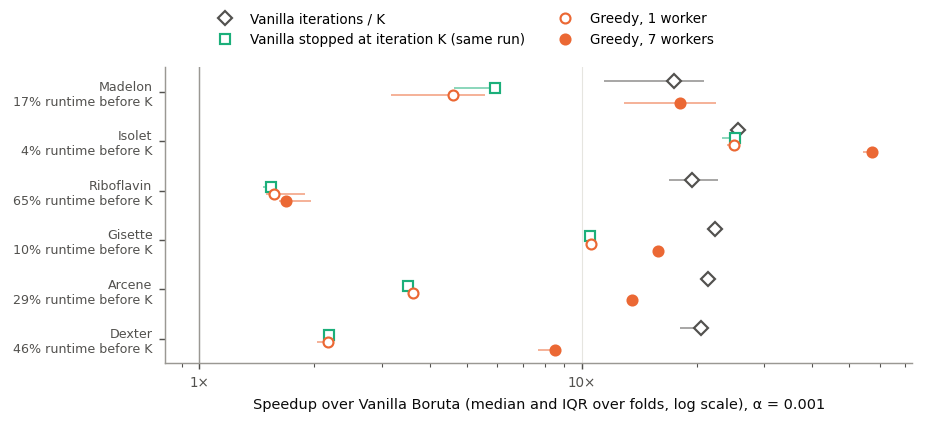

In [7]:
decomposition = ah.speedup_decomposition(paired, complete, histories)
focus = decomposition[decomposition.Alpha.eq(FOCUS_ALPHA)].pivot_table(index="Dataset", columns="Quantity", values="Median")
display(focus.round(2))
show(ah.speedup_plot(decomposition, FOCUS_ALPHA, REAL, histories, PARALLEL_Q), "fig_speedup")
real_dec = decomposition[decomposition.Dataset.isin(REAL)]
for quantity in ["Greedy serial (j=1)", PARALLEL_Q, "Same run stopped at K (history)", "Iteration ratio"]:
    values = real_dec[real_dec.Quantity.eq(quantity)].Median
    if len(values):
        FACTS[f"real_median_speedup_range::{quantity}"] = [round(values.min(), 1), round(values.max(), 1)]
if HAS_HISTORY:
    compare = focus.loc[REAL, ["Same run stopped at K (history)", "Greedy serial (j=1)"]]
    FACTS["serial_vs_stopped_at_K_ratio"] = (compare.iloc[:, 1] / compare.iloc[:, 0]).round(2).to_dict()

**Compute, not only wall clock.** CPU-seconds and sampled peak RSS increase at the focus α.

In [8]:
cost = complete[complete.Alpha.eq(FOCUS_ALPHA) & complete.Label.isin(["Vanilla rough fix", ah.PAPER_GREEDY, PARALLEL])]
cost = cost.groupby(["Dataset", "Label"]).agg(Time=("Selection_Time_Sec", "median"), CPU=("Selection_CPU_Sec", "median"),
                                              RSS=("RSS_Peak_Increase_MB", "median")).unstack("Label")
cpu_ratio = (cost["CPU"]["Vanilla rough fix"] / cost["CPU"][[ah.PAPER_GREEDY, PARALLEL]].T).T
display(cost.loc[REAL + SYNTHETIC].round(1))
display(cpu_ratio.loc[REAL].rename(columns=lambda c: f"Vanilla CPU / {c}").round(2))
parallel = ah.parallel_ablation(complete)
FACTS["parallel_identical_mask_fraction"] = float(parallel.Identical_Mask.mean())
FACTS["parallel_pairs"] = int(len(parallel))
FACTS["cpu_ratio_parallel_real"] = cpu_ratio.loc[REAL, PARALLEL].round(2).to_dict()
FACTS["cpu_ratio_serial_real"] = cpu_ratio.loc[REAL, ah.PAPER_GREEDY].round(2).to_dict()
FACTS["rss_increase_mb_real"] = cost["RSS"].loc[REAL].round(0).to_dict()

Time                                               CPU                                               RSS                                  
Label           Greedy j=1, s=1 Greedy j=7, s=1 Vanilla rough fix Greedy j=1, s=1 Greedy j=7, s=1 Vanilla rough fix Greedy j=1, s=1 Greedy j=7, s=1 Vanilla rough fix
Dataset                                                                                                                                                              
Madelon                    11.5             2.9              51.6            27.4            36.4              83.1            32.7           279.1              40.6
Isolet                     14.5             6.2             361.2            78.8           133.0            1945.4           118.4          1110.6             147.8
Riboflavin                 70.4            65.4             118.6          1574.1          1492.9            1663.0           118.1           304.9             106.4
Gisette                    66.0            43.9             695.9           792.5           952.6            5251.0           576.9          3968.8             728.6
Arcene                     49.3            13.1             178.8            97.2           148.2             249.7           602.5          4096.3             697.2
Dexter                     82.4            21.0             179.4           177.0           279.8             283.9          2090.3         16291.4            2110.2
reference                   7.5             2.0              30.5            14.1            21.5              39.8            13.2           110.4              16.4
n_features_2000            17.6             7.0              59.4            50.3           126.5              95.0            59.3           441.5              64.2
signal_0.5                 14.1             2.6              45.4            25.8            27.3              56.5            13.2           108.2              16.2
kind_null                  14.2             2.6              22.8            25.8            27.3              33.6            13.2           108.2              16.2

Label,"Vanilla CPU / Greedy j=1, s=1","Vanilla CPU / Greedy j=7, s=1"
Dataset,,
Madelon,3.03,2.28
Isolet,24.67,14.63
Riboflavin,1.06,1.11
Gisette,6.63,5.51
Arcene,2.57,1.68
Dexter,1.60,1.01


## 4.3 Selection quality against ground truth

Mean false positives per fold versus α with the Theorem 3 bound E[FP] <= m0 K/(p+1)
(whiskers: IQR over folds), then the hit counts of Greedy's selections (coupled run).

In [9]:
title_aux = {
    "reference": "Reference",
    "n_features_2000": "High-dimensional",
    "signal_0.5": "Weak signal",
    "kind_null": "Null",
}

title_aux.get('reference')

'Reference'

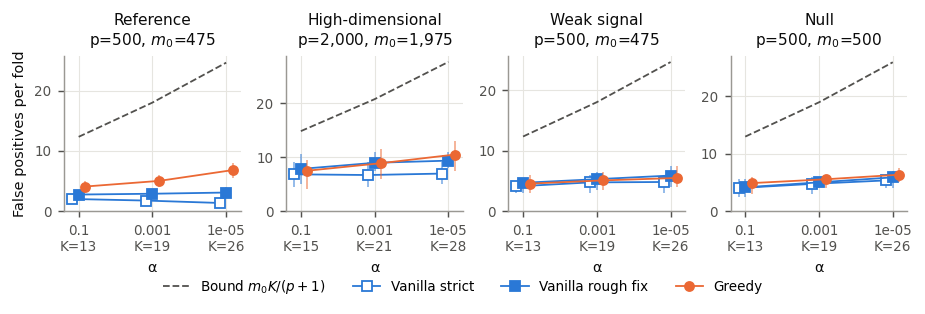

,Dataset,Alpha,Label,Recall_mean,Precision_mean,FP_mean,FP_median,FPR_mean,K,Bound_E_FP,FP_over_bound
145,kind_null,1.0000e-05,"Greedy j=1, s=1",NaN,0.0000,6.3333,6.0,0.0127,26,25.9481,0.2441
150,kind_null,1.0000e-05,Vanilla rough fix,NaN,0.0000,5.8667,6.0,0.0117,26,25.9481,0.2261
151,kind_null,1.0000e-05,Vanilla strict,NaN,0.0000,5.3333,6.0,0.0107,26,25.9481,0.2055
153,kind_null,1.0000e-03,"Greedy j=1, s=1",NaN,0.0000,5.5333,6.0,0.0111,19,18.9621,0.2918
158,kind_null,1.0000e-03,Vanilla rough fix,NaN,0.0000,5.0000,5.0,0.0100,19,18.9621,0.2637
159,kind_null,1.0000e-03,Vanilla strict,NaN,0.0000,4.7333,5.0,0.0095,19,18.9621,0.2496
161,kind_null,1.0000e-01,"Greedy j=1, s=1",NaN,0.0000,4.8667,5.0,0.0097,13,12.9741,0.3751
166,kind_null,1.0000e-01,Vanilla rough fix,NaN,0.0000,4.1333,4.0,0.0083,13,12.9741,0.3186
167,kind_null,1.0000e-01,Vanilla strict,NaN,0.0000,4.0000,4.0,0.0080,13,12.9741,0.3083
193,n_features_2000,1.0000e-05,"Greedy j=1, s=1",1.0000,0.7110,10.4667,11.0,0.0053,28,27.6362,0.3787


In [10]:
show(ah.fp_bound_plot(complete, run.manifest, SYNTHETIC), "fig_fp_vs_bound")
gt = summary[summary.Dataset.isin(SYNTHETIC) & summary.Label.isin(["Vanilla strict", "Vanilla rough fix", ah.PAPER_GREEDY])]
gt = gt[["Dataset", "Alpha", "Label", "Recall_mean", "Precision_mean", "FP_mean", "FP_median", "FPR_mean"]].copy()
gt["K"] = [int(np.ceil(np.log2(datasets[d][1]["n_features"] / a))) for d, a in zip(gt.Dataset, gt.Alpha)]
gt["Bound_E_FP"] = [(datasets[d][1]["n_features"] - len(ah.relevant_features(datasets[d][1]))) * k
                    / (datasets[d][1]["n_features"] + 1) for d, k in zip(gt.Dataset, gt.K)]
gt["FP_over_bound"] = gt.FP_mean / gt.Bound_E_FP
display(gt)
greedy_gt = gt[gt.Label.eq(ah.PAPER_GREEDY)]
FACTS["greedy_fp_over_bound_range"] = [round(greedy_gt.FP_over_bound.min(), 2), round(greedy_gt.FP_over_bound.max(), 2)]
FACTS["null_fp_mean"] = gt[gt.Dataset.eq("kind_null")].pivot_table(index="Alpha", columns="Label", values="FP_mean").round(2).to_dict()
FACTS["fp_mean_focus"] = gt[gt.Alpha.eq(FOCUS_ALPHA)].pivot_table(index="Dataset", columns="Label", values="FP_mean").round(2).to_dict()
FACTS["recall_focus"] = gt[gt.Alpha.eq(FOCUS_ALPHA)].pivot_table(index="Dataset", columns="Label", values="Recall_mean").round(3).to_dict()
FACTS["fpr_by_p_greedy"] = greedy_gt[greedy_gt.Alpha.eq(FOCUS_ALPHA)].set_index("Dataset").FPR_mean.round(4).to_dict()

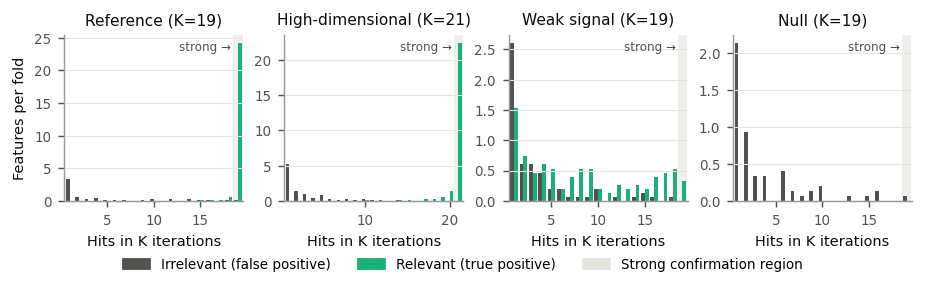

,Dataset,Alpha,Greedy,Strong,Weak,FP,FP_Strong,FP_Weak,Share_of_FP_in_weak
0,kind_null,1.0000e-05,5.8667,0.0667,5.8000,5.8667,0.0667,5.8000,0.9886
1,kind_null,1.0000e-03,5.0000,0.0667,4.9333,5.0000,0.0667,4.9333,0.9867
2,kind_null,1.0000e-01,4.1333,0.0667,4.0667,4.1333,0.0667,4.0667,0.9839
3,n_features_2000,1.0000e-05,35.7333,22.0667,13.6667,10.7333,0.0000,10.7333,1.0000
4,n_features_2000,1.0000e-03,35.0000,22.3333,12.6667,10.0000,0.0000,10.0000,1.0000
5,n_features_2000,1.0000e-01,33.6667,23.4000,10.2667,8.6667,0.0000,8.6667,1.0000
6,reference,1.0000e-05,31.8667,24.0667,7.8000,6.8667,0.0000,6.8667,1.0000
7,reference,1.0000e-03,31.2667,24.2000,7.0667,6.2667,0.0667,6.2000,0.9894
8,reference,1.0000e-01,30.4667,24.5333,5.9333,5.4667,0.0667,5.4000,0.9878
9,signal_0.5,1.0000e-05,15.0000,0.2667,14.7333,6.0667,0.0000,6.0667,1.0000


count  mean  std   min   25%   50%   75%   max
Dataset         Relevant                                                
kind_null       False      75.0   3.7  4.2   1.0   1.0   2.0   5.0  19.0
n_features_2000 False     150.0   2.8  2.7   1.0   1.0   1.0   3.0  14.0
                True      375.0  20.8  1.0  10.0  21.0  21.0  21.0  21.0
reference       False      94.0   4.0  4.8   1.0   1.0   1.0   4.8  19.0
                True      375.0  18.9  0.4  15.0  19.0  19.0  19.0  19.0
signal_0.5      False      82.0   3.5  4.0   1.0   1.0   2.0   4.0  18.0
                True      128.0   8.1  6.1   1.0   2.0   7.0  14.0  19.0

In [11]:
if HAS_COUPLED:
    show(ah.hits_plot(complete, run.manifest, FOCUS_ALPHA, SYNTHETIC), "fig_hits")
    synth_sets = sets[sets.Dataset.isin(SYNTHETIC)]
    weak_strong = synth_sets.groupby(["Dataset", "Alpha"]).agg(
        Greedy=("N_Greedy", "mean"), Strong=("N_Strong", "mean"), Weak=("N_Weak", "mean"),
        FP=("FP_Greedy", "mean"), FP_Strong=("FP_Strong", "mean"), FP_Weak=("FP_Weak", "mean")).reset_index()
    weak_strong["Share_of_FP_in_weak"] = weak_strong.FP_Weak / weak_strong.FP
    display(weak_strong)
    hits = []
    for row in complete[complete.Method.eq(ah.COUPLED) & complete.Dataset.isin(SYNTHETIC) & complete.Alpha.eq(FOCUS_ALPHA)].itertuples():
        truth = ah.relevant_features(datasets[row.Dataset][1])
        hits += [dict(Dataset=row.Dataset, Relevant=j in truth, Hits=h, K=row.Iterations)
                 for j, h in zip(row.Selected_Features, row.Selected_Hits)]
    hits = pd.DataFrame(hits)
    display(hits.groupby(["Dataset", "Relevant"]).Hits.describe().round(1))
    FACTS["share_fp_weak_range"] = [round(weak_strong.Share_of_FP_in_weak.min(), 3), round(weak_strong.Share_of_FP_in_weak.max(), 3)]
    FACTS["fp_hits_share_1_or_2"] = round(float(hits[~hits.Relevant].Hits.le(2).mean()), 3)
    FACTS["fp_hits_median"] = float(hits[~hits.Relevant].Hits.median())
    FACTS["tp_hits_over_K_median_by_dataset"] = (hits[hits.Relevant].assign(r=lambda d: d.Hits / d.K)
                                                  .groupby("Dataset").r.median().round(2).to_dict())
else:
    display(Markdown("_Coupled Greedy not available yet._"))

## 4.4 Real-world benchmarks

**Which features does Greedy add?** Each coupled Greedy selection splits into nested
layers (Strong ⊆ Vanilla strict ⊆ Vanilla rough fix ⊆ Greedy, verified exactly).

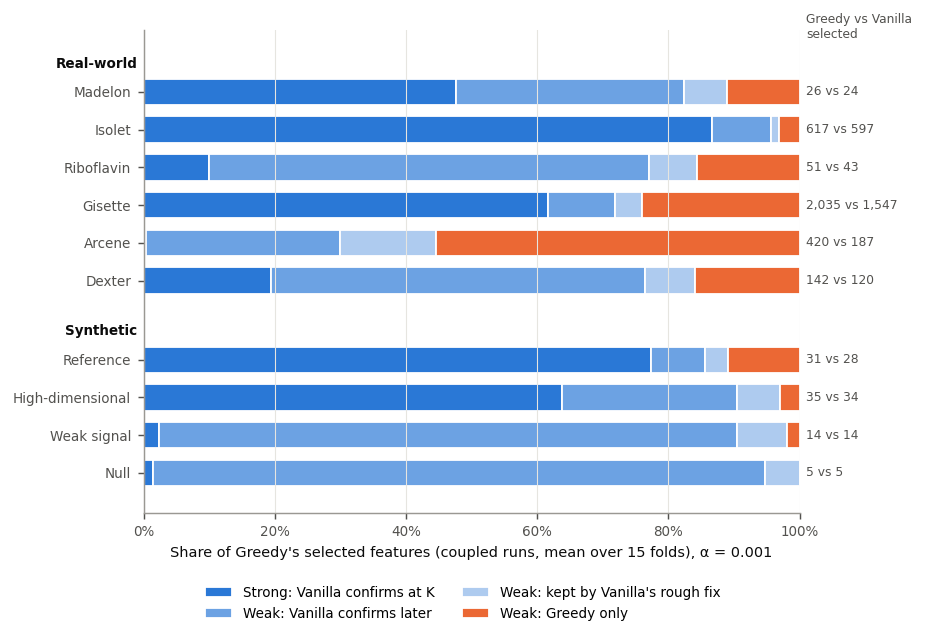

Strong (Vanilla confirms at K)  Vanilla confirms after K  Vanilla rough fix  Greedy only  N_Greedy  N_Vanilla_Rough_Fix  N_Strong  N_Weak
Dataset         Alpha                                                                                                                                                
Arcene          1.0000e-05                             0.8                     114.1               70.3        265.1     450.3                185.2       0.8   449.5
                1.0000e-03                             1.1                     124.7               60.9        232.9     419.7                186.8       1.1   418.5
                1.0000e-01                             1.5                     135.1               46.5        191.0     374.1                183.1       1.5   372.5
Dexter          1.0000e-05                            26.1                      82.5               12.0         24.6     145.1                120.5      26.1   119.1
                1.0000e-03                            27.7                      81.1               10.9         22.8     142.4                119.6      27.7   114.7
                1.0000e-01                            31.9                      75.9                8.3         19.8     135.8                116.0      31.9   103.9
Gisette         1.0000e-05                          1233.1                     216.6              103.9        496.9    2050.5               1553.6    1233.1   817.4
                1.0000e-03                          1255.9                     207.1               84.3        488.1    2035.3               1547.3    1255.9   779.4
                1.0000e-01                          1294.1                     188.6               66.9        458.9    2008.5               1549.5    1294.1   714.4
Isolet          1.0000e-05                           529.1                      59.4                8.9         19.7     617.0                597.3     529.1    87.9
                1.0000e-03                           534.0                      55.9                7.5         19.5     616.9                597.3     534.0    82.9
                1.0000e-01                           543.1                      48.3                5.9         19.0     616.3                597.3     543.1    73.2
Madelon         1.0000e-05                            12.4                       9.1                2.5          3.5      27.5                 24.0      12.4    15.1
                1.0000e-03                            12.6                       9.2                1.7          2.9      26.5                 23.5      12.6    13.9
                1.0000e-01                            12.7                       9.3                1.4          2.1      25.6                 23.5      12.7    12.9
Riboflavin      1.0000e-05                             4.0                      34.3                4.3          8.8      51.4                 42.6       4.0    47.4
                1.0000e-03                             5.1                      34.2                3.7          8.0      51.0                 43.0       5.1    45.9
                1.0000e-01                             6.1                      32.9                2.8          6.5      48.3                 41.8       6.1    42.3
kind_null       1.0000e-05                             0.1                       5.3                0.5          0.0       5.9                  5.9       0.1     5.8
                1.0000e-03                             0.1                       4.7                0.3          0.0       5.0                  5.0       0.1     4.9
                1.0000e-01                             0.1                       3.9                0.1          0.0       4.1                  4.1       0.1     4.1
kind_xor        1.0000e-05                             0.0                       7.6                0.9          0.1       8.5                  8.5       0.0     8.5
                1.0000e-03                  

Final Vanilla decision for Greedy's **weak** features (history refits, shares):

,Weak_Confirmed,Weak_Tentative_Promoted,Weak_Tentative_Dropped,Weak_Rejected
Dataset,,,,
Arcene,0.304,0.141,0.060,0.496
Dexter,0.713,0.077,0.017,0.193
Gisette,0.260,0.105,0.113,0.523
Isolet,0.676,0.097,0.057,0.170
Madelon,0.660,0.128,0.106,0.106
Riboflavin,0.667,0.079,0.061,0.193
kind_null,0.952,0.048,0.000,0.000
kind_xor,0.880,0.120,0.000,0.000
n_features_2000,0.676,0.189,0.027,0.108


In [12]:
if HAS_COUPLED:
    show(ah.fates_plot(sets, FOCUS_ALPHA, {"Real-world": REAL, "Synthetic": SYNTHETIC}), "fig_greedy_fates")
    fates = sets.groupby(["Dataset", "Alpha"])[ah.FATE_LAYERS + ["N_Greedy", "N_Vanilla_Rough_Fix", "N_Strong", "N_Weak"]].mean()
    display(fates.round(1))
    focus_fates = fates.xs(FOCUS_ALPHA, level="Alpha")
    FACTS["greedy_only_share_focus"] = (focus_fates["Greedy only"] / focus_fates.N_Greedy).round(3).to_dict()
    FACTS["vanilla_share_of_greedy_focus"] = (focus_fates.N_Vanilla_Rough_Fix / focus_fates.N_Greedy).round(3).to_dict()
    FACTS["strong_share_focus"] = (focus_fates.N_Strong / focus_fates.N_Greedy).round(3).to_dict()
    if HAS_HISTORY:
        weak = ah.history_fates(RUN_DIR, complete)
        weak = weak[weak.Alpha.eq(FOCUS_ALPHA)].groupby("Dataset").sum(numeric_only=True)
        shares = weak[["Weak_Confirmed", "Weak_Tentative_Promoted", "Weak_Tentative_Dropped", "Weak_Rejected"]].div(weak.N_Weak, axis=0)
        display(Markdown("Final Vanilla decision for Greedy's **weak** features (history refits, shares):"))
        display(shares.round(3))
        FACTS["weak_final_decision_shares"] = shares.round(3).to_dict()
        median_iter = ah.history_fates(RUN_DIR, complete).groupby("Dataset").Weak_Median_Decision_Iteration.median()
        FACTS["weak_median_decision_iteration"] = median_iter.round(0).to_dict()
else:
    display(Markdown("_Coupled Greedy not available yet._"))

**Independent versus coupled.** Same algorithm, different random streams: sizes and scores
should agree in distribution, and sharing the stream should shrink the spread of the paired
differences (descriptive only; the confirmatory test stays prespecified).

In [12]:
if HAS_COUPLED:
    agree = summary[summary.Label.isin([ah.PAPER_GREEDY, "Greedy coupled"]) & summary.Alpha.eq(FOCUS_ALPHA)].pivot_table(
        index="Dataset", columns="Label", values=["N_Selected_mean", "Score_mean"])
    display(agree.loc[REAL + SYNTHETIC].round(3))
    spread = paired[paired.Label.isin([ah.PAPER_GREEDY, "Greedy coupled"]) & paired.Alpha.eq(FOCUS_ALPHA)].groupby(
        ["Dataset", "Label"]).Score_Difference.std().unstack()
    spread["Reduction"] = 1 - spread["Greedy coupled"] / spread[ah.PAPER_GREEDY]
    display(spread.loc[REAL].round(4))
    FACTS["coupled_sd_reduction_real"] = spread.loc[REAL, "Reduction"].round(2).to_dict()

N_Selected_mean                     Score_mean                
Label            Greedy coupled Greedy j=1, s=1 Greedy coupled Greedy j=1, s=1
Dataset                                                                       
Madelon                  26.467          26.467          0.848           0.851
Isolet                  616.867         616.733          0.958           0.958
Riboflavin               51.000          47.533          0.421           0.446
Gisette                2035.333        2035.067          0.983           0.982
Arcene                  419.667         407.267          0.808           0.810
Dexter                  142.400         142.733          0.937           0.938
reference                31.267          30.000          0.760           0.766
n_features_2000          35.000          33.867          0.711           0.714
signal_0.5               14.000          13.600          0.534           0.536
kind_null                 5.000           5.533          0.501           0.496

Label,Greedy coupled,"Greedy j=1, s=1",Reduction
Dataset,,,
Madelon,0.0097,0.0152,0.3577
Isolet,0.0023,0.0025,0.1006
Riboflavin,0.0663,0.0877,0.2436
Gisette,0.0020,0.0028,0.2895
Arcene,0.0428,0.0596,0.2824
Dexter,0.0049,0.0100,0.5033


**Prespecified non-inferiority** (margin 0.01, one-sided level 0.01, Holm over the full
planned family) with the **0.025 sensitivity bound** (black tick). *All features* (no
selection) calibrates the test: where it also passes, the test cannot discriminate selectors.

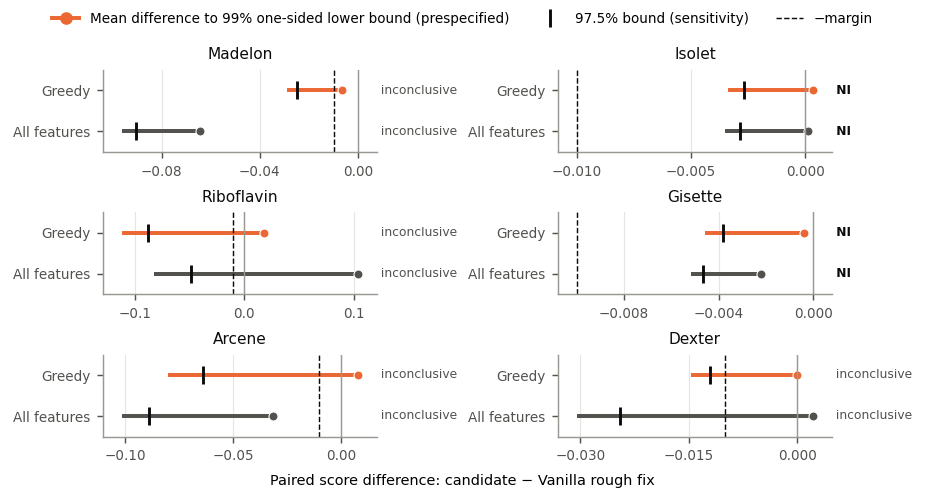

,Dataset,Alpha,Label,Mean_Difference,Corrected_SE,Lower_One_Sided_CI,Lower_Bound_97.5,P_NI_Holm,Decision,Decision_Level_0.025
0,Arcene,1.0000e-05,"Greedy j=1, s=1",6.4937e-03,0.0296,-0.0712,-0.0570,1.0000e+00,Non-inferiority not established,Non-inferiority not established
4,Arcene,1.0000e-05,All features,-2.9599e-02,0.0201,-0.0822,-0.0726,1.0000e+00,Non-inferiority not established,Non-inferiority not established
5,Arcene,1.0000e-03,"Greedy j=1, s=1",8.0543e-03,0.0335,-0.0800,-0.0639,1.0000e+00,Non-inferiority not established,Non-inferiority not established
9,Arcene,1.0000e-03,All features,-3.1341e-02,0.0268,-0.1016,-0.0887,1.0000e+00,Non-inferiority not established,Non-inferiority not established
10,Arcene,1.0000e-01,"Greedy j=1, s=1",1.1901e-02,0.0307,-0.0687,-0.0540,1.0000e+00,Non-inferiority not established,Non-inferiority not established
14,Arcene,1.0000e-01,All features,-3.0695e-02,0.0330,-0.1173,-0.1015,1.0000e+00,Non-inferiority not established,Non-inferiority not established
15,Dexter,1.0000e-05,"Greedy j=1, s=1",1.6715e-03,0.0057,-0.0132,-0.0105,1.0000e+00,Non-inferiority not established,Non-inferiority not established
19,Dexter,1.0000e-05,All features,3.3425e-03,0.0110,-0.0256,-0.0203,1.0000e+00,Non-inferiority not established,Non-inferiority not established
20,Dexter,1.0000e-03,"Greedy j=1, s=1",-4.5583e-06,0.0056,-0.0147,-0.0120,1.0000e+00,Non-inferiority not established,Non-inferiority not established
24,Dexter,1.0000e-03,All features,2.2212e-03,0.0125,-0.0305,-0.0245,1.0000e+00,Non-inferiority not established,Non-inferiority not established


In [13]:
show(ah.ni_forest_plot(ni, FOCUS_ALPHA, REAL), "fig_noninferiority")
cols = ["Dataset", "Alpha", "Label", "Mean_Difference", "Corrected_SE", "Lower_One_Sided_CI",
        "Lower_Bound_97.5", "P_NI_Holm", "Decision", "Decision_Level_0.025"]
display(ni[ni.Dataset.isin(REAL) & ni.Label.isin([ah.PAPER_GREEDY, "All features"])][cols])
greedy_ni = ni[ni.Dataset.isin(REAL) & ni.Label.eq(ah.PAPER_GREEDY)]
established = lambda col: sorted(set(greedy_ni.loc[greedy_ni[col].str.startswith("Non-inferiority established"), "Dataset"]))
FACTS["ni_established_greedy_real"] = {"level_0.01": established("Decision"), "level_0.025": established("Decision_Level_0.025"),
                                       "count_0.01": int(greedy_ni.Decision.str.startswith("Non-inferiority established").sum()),
                                       "of": int(len(greedy_ni))}
all_ni = ni[ni.Dataset.isin(REAL) & ni.Label.eq("All features")]
FACTS["ni_established_all_features_real"] = sorted(set(all_ni.loc[all_ni.Decision.str.startswith("Non-inferiority established"), "Dataset"]))
FACTS["greedy_mean_difference_within_margin"] = int(greedy_ni.Mean_Difference.ge(-greedy_ni.Margin).sum())
FACTS["greedy_mean_difference_focus"] = greedy_ni[greedy_ni.Alpha.eq(FOCUS_ALPHA)].set_index("Dataset").Mean_Difference.round(4).to_dict()

**Main table** (focus α in the main text; all α for the appendix).

In [14]:
alphas = sorted(config["alphas"], reverse=True)
main_table = ah.real_results_table(summary, ni, decomposition, [FOCUS_ALPHA], REAL, PARALLEL_Q)
full_table = ah.real_results_table(summary, ni, decomposition, alphas, REAL, PARALLEL_Q)
display(main_table)
notes = (r"$\bar D$: mean paired difference Greedy $-$ Vanilla rough fix; LB: one-sided lower bounds "
         r"(prespecified 99\%, sensitivity 97.5\%); NI: Holm-adjusted non-inferiority at margin 0.01, level 0.01.")
save_latex(main_table.drop(columns=r"$\alpha$"), "real_results_focus",
           f"Real-world benchmarks at $\\alpha={FOCUS_ALPHA:g}$.", "tab:realworld_results", notes=notes, group_rules=False)
save_latex(full_table, "real_results_all_alpha", "Real-world benchmarks at every $\\alpha$.",
           "tab:realworld_results_all", notes=notes);

,Dataset,$\alpha$,Vanilla,Greedy,$\bar D$,LB$_{99}$,LB$_{97.5}$,NI,\#sel.\ V/G,Speedup
0,Madelon,0.001,$0.858 \pm 0.019$,$0.851 \pm 0.017$,$-0.007$,$-0.029$,$-0.025$,--,24/26,4.6/18.1
1,Isolet,0.001,$0.958 \pm 0.004$,$0.958 \pm 0.004$,$+0.000$,$-0.003$,$-0.003$,\checkmark,597/617,25.0/57.2
2,Riboflavin,0.001,$0.429 \pm 0.220$,$0.446 \pm 0.171$,$+0.018$,$-0.112$,$-0.088$,--,43/48,1.6/1.7
3,Gisette,0.001,$0.983 \pm 0.004$,$0.982 \pm 0.004$,$-0.000$,$-0.005$,$-0.004$,\checkmark,1547/2035,10.6/15.8
4,Arcene,0.001,$0.801 \pm 0.073$,$0.810 \pm 0.067$,$+0.008$,$-0.080$,$-0.064$,--,187/407,3.6/13.5
5,Dexter,0.001,$0.938 \pm 0.022$,$0.938 \pm 0.022$,$-0.000$,$-0.015$,$-0.012$,--,120/143,2.2/8.5


**Sensitivity to α.** One marker per α on each dataset row: overlapping markers mean α
changes little beyond the iteration budget. The shaded band is the NI margin.

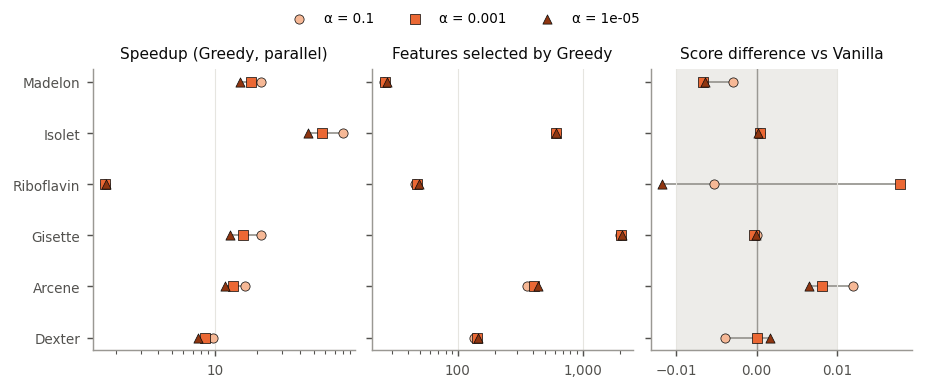

In [15]:
show(ah.alpha_strip_plot(paired, complete, run.manifest, REAL), "fig_alpha_sensitivity")

## Appendix B: reduced shadows

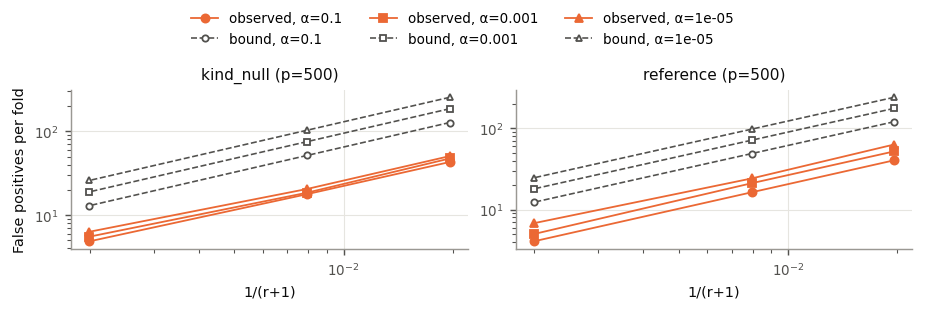

,Dataset,Alpha,Label,Shadows,Time,RSS,Selected,Score,FP,Recall
3,Arcene,0.001,"Greedy j=7, s=0.1",1000.0,11.0006,1766.2383,973.4667,0.8255,NaN,NaN
4,Arcene,0.001,"Greedy j=7, s=0.25",2500.0,11.3274,2771.5977,684.6667,0.8276,NaN,NaN
5,Arcene,0.001,"Greedy j=7, s=1",10000.0,13.0728,4096.2812,407.2667,0.8095,NaN,NaN
12,Dexter,0.001,"Greedy j=7, s=0.1",2000.0,16.3266,8973.3203,290.8000,0.9372,NaN,NaN
13,Dexter,0.001,"Greedy j=7, s=0.25",5000.0,17.2683,10656.5117,217.3333,0.9400,NaN,NaN
14,Dexter,0.001,"Greedy j=7, s=1",20000.0,21.0211,16291.3906,142.7333,0.9378,NaN,NaN
21,Gisette,0.001,"Greedy j=7, s=0.1",500.0,31.8950,2105.1328,2165.6000,0.9814,NaN,NaN
22,Gisette,0.001,"Greedy j=7, s=0.25",1250.0,34.2286,2374.2383,2090.4000,0.9825,NaN,NaN
23,Gisette,0.001,"Greedy j=7, s=1",5000.0,43.9227,3968.8438,2035.0667,0.9823,NaN,NaN
30,Isolet,0.001,"Greedy j=7, s=0.1",62.0,4.6143,648.5195,616.9333,0.9582,NaN,NaN


Label,"Greedy j=7, s=0.1","Greedy j=7, s=0.25","Greedy j=7, s=1"
Dataset,,,
Arcene,0.0241,0.0261,0.0081
Dexter,-0.0006,0.0022,-0.0000
Gisette,-0.0013,-0.0002,-0.0004
Isolet,0.0003,0.0003,0.0004
Madelon,-0.0529,-0.0319,-0.0067
Riboflavin,0.0504,0.0469,0.0178
kind_null,0.0058,-0.0092,-0.0049
kind_xor,-0.0003,-0.0010,-0.0213
n_features_2000,-0.0042,-0.0106,-0.0002


In [16]:
shadow_scenarios = [n for n in ["kind_null", "reference"] if n in datasets]
show(ah.shadow_fp_plot(complete, run.manifest, shadow_scenarios), "fig_shadow_fp")
reduced = complete[complete.Method.str.match(r"Greedy_jobs\d+_shadows") & complete.Outer_Jobs.eq(complete.Outer_Jobs.max())]
shadow = reduced.groupby(["Dataset", "Alpha", "Label"]).agg(
    Shadows=("N_Shadows", "first"), Time=("Selection_Time_Sec", "median"),
    RSS=("RSS_Peak_Increase_MB", "median"), Selected=("N_Selected", "mean"), Score=("Score", "mean"),
    FP=("FP", "mean"), Recall=("Recall", "mean")).reset_index()
display(shadow[shadow.Alpha.eq(FOCUS_ALPHA)])
shadow_diff = paired[paired.Method.isin(reduced.Method.unique())].groupby(
    ["Dataset", "Alpha", "Label"]).Score_Difference.mean().unstack("Label")
display(shadow_diff.xs(FOCUS_ALPHA, level="Alpha").round(4))

## Appendix C: synthetic runtime anatomy and speedup, XOR, stability

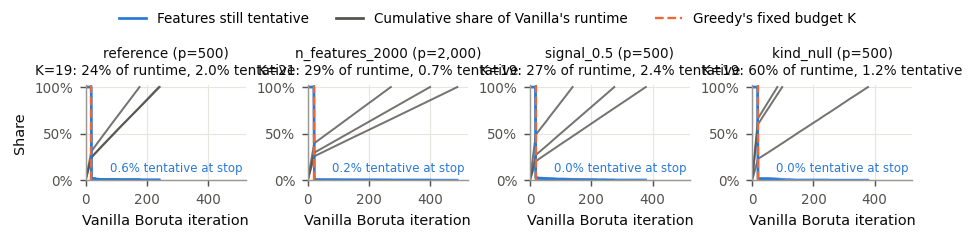

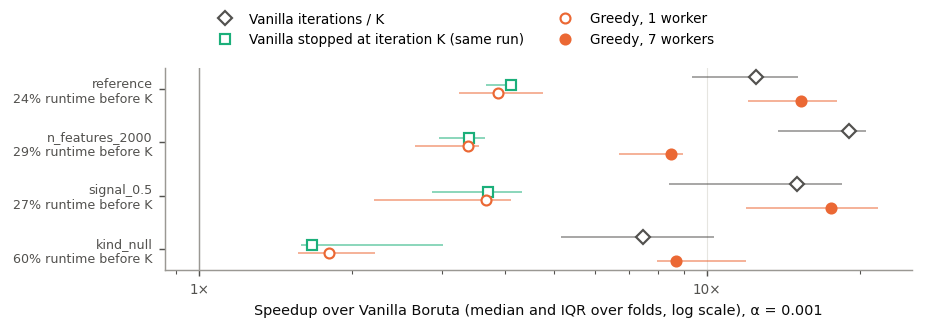

,Dataset,Alpha,Label,Recall_mean,FP_mean,Score_mean
168,kind_xor,1.0000e-05,Greedy coupled,0.0000,8.5333,0.5038
169,kind_xor,1.0000e-05,"Greedy j=1, s=1",0.0333,8.4667,0.4873
170,kind_xor,1.0000e-05,"Greedy j=7, s=0.1",0.2333,52.4667,0.5111
171,kind_xor,1.0000e-05,"Greedy j=7, s=0.25",0.0667,26.1333,0.5030
172,kind_xor,1.0000e-05,"Greedy j=7, s=1",0.0333,8.4667,0.4873
173,kind_xor,1.0000e-05,All features,1.0000,498.0000,0.5103
174,kind_xor,1.0000e-05,Vanilla rough fix,0.0000,8.4667,0.5045
175,kind_xor,1.0000e-05,Vanilla strict,0.0000,7.6000,0.5046
176,kind_xor,1.0000e-03,Greedy coupled,0.0000,7.2667,0.5084
177,kind_xor,1.0000e-03,"Greedy j=1, s=1",0.0000,7.4000,0.4852


Label,Greedy coupled,"Greedy j=1, s=1",Vanilla rough fix
Dataset,,,
Arcene,0.382,0.372,0.383
Dexter,0.642,0.639,0.689
Gisette,0.947,0.947,0.942
Isolet,1.000,0.999,0.993
Madelon,0.667,0.656,0.758
Riboflavin,0.340,0.336,0.349
kind_null,0.225,0.171,0.225
kind_xor,0.170,0.157,0.172
n_features_2000,0.643,0.669,0.668


In [17]:
if HAS_HISTORY:
    show(ah.runtime_anatomy_plot(trajectories, FOCUS_ALPHA, SYNTHETIC, ncols=4), "fig_runtime_anatomy_synthetic")
show(ah.speedup_plot(decomposition, FOCUS_ALPHA, SYNTHETIC, histories, PARALLEL_Q), "fig_speedup_synthetic")
xor = [n for n, (kind, spec) in datasets.items() if kind == "synthetic" and spec["kind"] == "xor"]
display(summary[summary.Dataset.isin(xor)][["Dataset", "Alpha", "Label", "Recall_mean", "FP_mean", "Score_mean"]])
stability, _ = ah.stability_tables(complete, run.manifest)
display(stability[stability.Alpha.eq(FOCUS_ALPHA) & stability.Label.isin(
    ["Vanilla rough fix", ah.PAPER_GREEDY, "Greedy coupled"])].pivot_table(
    index="Dataset", columns="Label", values="Mean_Pairwise_Jaccard").round(3))

## Key numbers and exports

In [18]:
def plain(value):
    if isinstance(value, dict):
        return {str(k): plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [plain(v) for v in value]
    return value.item() if hasattr(value, "item") else value

(OUTPUT_DIR / "key_numbers.json").write_text(json.dumps(plain(FACTS), indent=2), encoding="utf-8")
for name, table in {"convergence": convergence, "speedup_decomposition": decomposition,
                    "ground_truth": gt, "noninferiority": ni, "coupled_sets": sets,
                    "vanilla_histories": histories}.items():
    if isinstance(table, pd.DataFrame) and not table.empty:
        table.to_csv(OUTPUT_DIR / "tables" / f"{name}.csv", index=False)
print(json.dumps(plain(FACTS), indent=1)[:8000])
print(f"Exported to {OUTPUT_DIR.relative_to(ROOT)}")

{
 "coupled_identity_checks": {
  "Theorem1_Strict": "495/495",
  "Theorem1_Rough_Fix": "495/495",
  "Strong_In_Strict": "495/495",
  "K_Matches_Greedy": "495/495"
 },
 "vanilla_cap_fraction_by_dataset_alpha": {
  "('Arcene', 1e-05)": 1.0,
  "('Arcene', 0.001)": 1.0,
  "('Arcene', 0.1)": 1.0,
  "('Dexter', 1e-05)": 0.933,
  "('Dexter', 0.001)": 0.6,
  "('Dexter', 0.1)": 0.467,
  "('Gisette', 1e-05)": 1.0,
  "('Gisette', 0.001)": 1.0,
  "('Gisette', 0.1)": 1.0,
  "('Isolet', 1e-05)": 0.933,
  "('Isolet', 0.001)": 0.667,
  "('Isolet', 0.1)": 0.667,
  "('Madelon', 1e-05)": 0.0,
  "('Madelon', 0.001)": 0.067,
  "('Madelon', 0.1)": 0.0,
  "('Riboflavin', 1e-05)": 0.333,
  "('Riboflavin', 0.001)": 0.267,
  "('Riboflavin', 0.1)": 0.067
 },
 "datasets_always_at_cap": [
  "Arcene",
  "Gisette"
 ],
 "rough_fix_promoted_max": 119,
 "rough_fix_used_fraction_real": {
  "('Arcene', 1e-05)": 1.0,
  "('Arcene', 0.001)": 1.0,
  "('Arcene', 0.1)": 1.0,
  "('Dexter', 1e-05)": 1.0,
  "('Dexter', 0.001)": 